# Mini-Projet Séries Temporelles — Partie 6
## Prévision multi-horizon et évaluation comparative — AAPL & QQQ

| Section | Contenu | Barème |
|---|---|---|
| **6.1** | Prévisions à **h = 1 … 10 jours** pour **tous les modèles** du projet (ARIMA, marche aléatoire, VAR, GARCH, LSTM, GRU, hybrides) | Bloc A |
| **6.2** | **Intervalles de prédiction** : analytiques (ARIMA, VAR, GARCH) et *conformaux* (réseaux) ; couverture et largeur réelles | Bloc A |
| **6.3** | **Tableau récapitulatif unique** : MSE, RMSE, MAE, MAPE + **test de Diebold-Mariano** | Bloc A |
| **6.4** | **Conclusion explicite** : meilleur modèle selon le cas d'usage (performance, interprétabilité, coût) | Bloc A |

**Exécution** : *Kernel → Restart & Run All*. `QUICK_RUN = True` (cellule de configuration) pour un test rapide.
**Prérequis** : les fichiers de la partie 4 (`../outputs/walkforward_grid_part4.csv`, `results_part4.csv`) servent à reprendre les hyper-paramètres retenus et à recouper les résultats ; s'ils sont absents, des valeurs par défaut sont utilisées (signalé à l'écran).

## Étape 0 — Configuration, reproductibilité et reprise des données

In [105]:
# === Configuration & imports ==========================================================
# Pourquoi en premier : tout ce qui conditionne la reproductibilité (graine, versions, chemins, hyper-paramètres)
# est centralisé ici pour qu'un correcteur puisse relancer l'étude à l'identique.
import os, re, json, time, warnings, platform, contextlib, io
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"       # moins de messages TensorFlow
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"       # calculs plus reproductibles d'une machine à l'autre
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display, Markdown
from scipy import stats
from scipy.optimize import minimize

import statsmodels, scipy, sklearn
from statsmodels.tsa.stattools import adfuller, grangercausalitytests
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.api import VAR
from statsmodels.tsa.regime_switching.markov_regression import MarkovRegression
from arch import arch_model
import arch as arch_pkg

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# ---- Paramètres généraux (modifiables) -----------------------------------------------
QUICK_RUN = False                         # True = test rapide (3 époques, 1 graine) : sert seulement à vérifier que tout tourne
SEED      = 42
H         = 10                            # horizon maximal de prévision (énoncé : h = 5 à 10)
ALPHA     = 0.05                          # niveau des intervalles de prédiction (95 %)
CSV_PATH  = "../data/data_aapl_qqq.csv"   # même fichier que l'équipe
EXOG_PATH = "../data/data_exog.csv"       # cache VIX / taux 10 ans (partie 7.1) ; à joindre à l'archive pour un usage hors-ligne
NEWS_PATH = "../data/news.csv"            # corpus d'actualités OPTIONNEL (colonnes : date, headline) — partie 7.3
OUT_DIR   = "../outputs"
for d in (OUT_DIR, "../data"): os.makedirs(d, exist_ok=True)

# ---- Hyper-paramètres des réseaux (mêmes principes que la partie 4) -------------------
CFG = dict(dropout=0.2, lr=1e-3, batch=32, max_epochs=80, patience=8, val_frac=0.15, n_seeds=3)
if QUICK_RUN: CFG.update(max_epochs=3, patience=2, n_seeds=1)

np.random.seed(SEED); keras.utils.set_random_seed(SEED); tf.get_logger().setLevel("ERROR")
try: tf.config.experimental.enable_op_determinism()
except Exception: pass
sns.set_theme(style="whitegrid"); plt.rcParams["figure.figsize"] = (12, 4.5)

print("Python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__, "| statsmodels", statsmodels.__version__,
      "| arch", arch_pkg.__version__, "| scikit-learn", sklearn.__version__, "| tensorflow", tf.__version__)
print("QUICK_RUN =", QUICK_RUN, "| H =", H, "| niveau des intervalles =", f"{100*(1-ALPHA):.0f} %", "|", CFG)

Python 3.13.16 | numpy 2.1.3 | pandas 2.2.3 | statsmodels 0.15.0 | arch 8.0.0 | scikit-learn 1.6.1 | tensorflow 2.21.0
QUICK_RUN = False | H = 10 | niveau des intervalles = 95 % | {'dropout': 0.2, 'lr': 0.001, 'batch': 32, 'max_epochs': 80, 'patience': 8, 'val_frac': 0.15, 'n_seeds': 3}


In [106]:
# === Étape 0b — rechargement des données de l'équipe (prix ET volumes) ================
# Pourquoi : notebook autonome ; mêmes formules que l'équipe (rendement log, MA20, volatilité 20 j, split chronologique 90/10).
def load_prices(csv_path=CSV_PATH):
    """Lit le CSV écrit par yf.download(...).to_csv (3 lignes d'en-tête). Renvoie prix ajustés et volumes."""
    if os.path.exists(csv_path):
        raw = pd.read_csv(csv_path, header=[0, 1], index_col=0)
        raw.index = pd.to_datetime(raw.index, errors="coerce")
        raw = raw[raw.index.notna()].astype(float)
        px, vol, src = raw["Adj Close"], raw["Volume"], f"CSV local : {csv_path}"
    else:
        import yfinance as yf
        data = yf.download(["AAPL", "QQQ"], start="2019-01-01", end="2026-10-01", auto_adjust=False, progress=False)
        px, vol, src = data["Adj Close"], data["Volume"], "yfinance (téléchargement direct)"
    return px[["AAPL", "QQQ"]].sort_index(), vol[["AAPL", "QQQ"]].sort_index(), src

prices, volume, source = load_prices()
assert prices.index.is_monotonic_increasing and not prices.index.duplicated().any() and not prices.isna().any().any()
returns = np.log(prices / prices.shift(1)).dropna()
dataset = pd.DataFrame({
    "AAPL": prices["AAPL"], "QQQ": prices["QQQ"],
    "AAPL_Return": returns["AAPL"], "QQQ_Return": returns["QQQ"],
    "AAPL_MA20": prices["AAPL"].rolling(20).mean(),
    "AAPL_Volatility20": returns["AAPL"].rolling(20).std()})
split_index = int(len(dataset) * 0.90)
train, test = dataset.iloc[:split_index].copy(), dataset.iloc[split_index:].copy()
print("Source :", source)
print(f"Période : {dataset.index[0].date()} → {dataset.index[-1].date()} | n = {len(dataset)} | train = {len(train)} | test = {len(test)}")
print("✔ identique au notebook de l'équipe (1947 / 1752 / 195)" if (len(dataset), len(train), len(test)) == (1947, 1752, 195)
      else "⚠ dimensions différentes de celles du notebook de l'équipe (1947 / 1752 / 195) : vérifier le fichier CSV")

Source : yfinance (téléchargement direct)
Période : 2019-01-02 → 2026-09-30 | n = 1947 | train = 1752 | test = 195
✔ identique au notebook de l'équipe (1947 / 1752 / 195)


In [107]:
# === Utilitaires communs (identiques à la partie 4 : mêmes métriques, mêmes tests) ====
def fit_scaler(F, cut):
    """Moyenne / écart-type calculés sur les lignes [0:cut] SEULEMENT (= information disponible à l'époque)."""
    return F[:cut].mean(axis=0), F[:cut].std(axis=0, ddof=0)

def price_metrics(y, yhat):
    e = np.asarray(y) - np.asarray(yhat)
    return dict(MSE=np.mean(e**2), RMSE=np.sqrt(np.mean(e**2)), MAE=np.mean(np.abs(e)), MAPE=100 * np.mean(np.abs(e / np.asarray(y))))

def diebold_mariano(e_model, e_ref, h=1, power=2):
    """DM (Harvey-Leybourne-Newbold). d_t = |e_model|^p − |e_ref|^p ; DM<0 ⇒ le modèle est meilleur que la référence.
    Pour un horizon h > 1 les erreurs se chevauchent : la variance est corrigée par h−1 autocovariances (HAC)."""
    d = np.abs(np.asarray(e_model))**power - np.abs(np.asarray(e_ref))**power
    T, dbar = len(d), d.mean()
    gam = lambda k: np.sum((d[k:] - dbar) * (d[:T - k] - dbar)) / T
    var = gam(0) + 2 * sum(gam(k) for k in range(1, h))
    if var <= 1e-18: return np.nan, np.nan
    dm = dbar / np.sqrt(var / T) * np.sqrt((T + 1 - 2*h + h*(h - 1) / T) / T)
    return float(dm), float(2 * (1 - stats.t.cdf(abs(dm), df=T - 1)))

def verdict(dm, p):
    if np.isnan(p): return "référence"
    if p < 0.05: return "significativement MEILLEUR" if dm < 0 else "significativement MOINS BON"
    return "différence non significative"

def best_config_from_part4():
    """Reprend les (fenêtre, unités) retenus par la validation walk-forward de la partie 4."""
    p = f"{OUT_DIR}/walkforward_grid_part4.csv"
    if os.path.exists(p):
        g = pd.read_csv(p); b = g.loc[g.groupby("modele")["ratio_moy"].idxmin()].set_index("modele")
        return {k: (int(r.fenetre), int(r.unites)) for k, r in b.iterrows()}, "partie 4 (walkforward_grid_part4.csv)"
    return {"LSTM": (10, 16), "GRU": (10, 16)}, "valeurs par défaut (fichier de la partie 4 introuvable)"
BEST, best_src = best_config_from_part4()
print("Hyper-paramètres des réseaux repris de la", best_src, ":", BEST)

Hyper-paramètres des réseaux repris de la partie 4 (walkforward_grid_part4.csv) : {'GRU': (10, 32), 'LSTM': (20, 32)}


## 6.0 — Protocole d'évaluation multi-horizon

**Problème de la prévision à un seul point de départ.** Prévoir 10 jours à partir de la fin du train donne 10 observations : aucune conclusion statistique n'est possible. On utilise donc une **évaluation à origine glissante** (*rolling origin*) :

> pour **chaque jour $t$ du jeu de test** (186 origines), chaque modèle (paramètres figés sur le train, information mise à jour jusqu'à $t$) prévoit les 10 jours suivants ; on compare à ce qui s'est réellement passé.

On obtient ainsi 186 erreurs par modèle et par horizon, d'où des métriques fiables et un **test de Diebold-Mariano** avec correction du chevauchement des erreurs.

**Une même grandeur pour tous les modèles** : le **rendement logarithmique cumulé** $R_{t,h}=\ln(P_{t+h}/P_t)$. Le prix prévu est $\hat P_{t+h}=P_t\,e^{\hat R_{t,h}}$.
- ARIMA(0,1,0) (marche aléatoire) : $\hat R=0$ → prix de la veille, comme dans l'ARIMA de l'équipe.
- Marche aléatoire + dérive : $\hat R=h\,\bar r_{train}$.
- VAR (rendements AAPL, QQQ) : prévision récursive, rendements sommés.
- GARCH(1,1) : moyenne constante ; son apport principal est la **volatilité**, donc les **intervalles**.
- LSTM / GRU (avec ou sans GARCH) : **réseaux multi-sorties directs** (un réseau prédit les 10 rendements d'un coup). On évite la prévision récursive car les entrées futures (rendement de QQQ, volatilité) sont inconnues.

**Aucun réglage sur le test** : les hyper-paramètres viennent de la validation walk-forward de la partie 4 (jeu d'apprentissage uniquement) ; le test n'est utilisé qu'une fois, pour juger.

**Intervalles de prédiction à 95 %** — selon ce que chaque modèle permet :
| Modèle | Méthode | Hypothèse clé |
|---|---|---|
| ARIMA(0,1,0) | analytique : $P_t \pm 1.96\,\sigma\sqrt h$ (σ constant, estimé sur le train, en euros) | variance constante en niveau |
| Marche aléatoire log + dérive | analytique sur les log-prix | variance constante des rendements |
| VAR | analytique (variance cumulée par la représentation MA) | variance constante des rendements |
| GARCH(1,1) | analytique : somme des variances conditionnelles prévues (la volatilité d'aujourd'hui compte) | normalité approchée de la somme (vérifiée par simulation) |
| Réseaux | **conformal split** : quantile 95 % des erreurs absolues sur un jeu de calibration (fin du train) | échangeabilité entre calibration et test |

**Qualité d'un intervalle** : *couverture* (part des réalisations dans l'intervalle ; cible 95 %), *largeur* moyenne, et *score de Winkler* (largeur + pénalité pour chaque dépassement : plus bas = mieux, il arbitre entre intervalles larges et trop étroits).

In [108]:
# === Tableaux de bord communs : variables, origines, valeurs réelles ===================
FEATURES_BASE = ["AAPL_Return", "QQQ_Return", "AAPL_Volatility20"]          # colonne 0 = cible
feat = dataset[FEATURES_BASE].dropna()
dates, T = feat.index, len(feat)
train_end = train.index[-1]
cut_final = int((dates <= train_end).sum())                                 # nb de lignes de la période d'apprentissage
F = feat.values.astype("float64")
PX = dataset.loc[dates, "AAPL"].values                                      # prix ajusté AAPL aligné sur `feat`

ORIG = np.arange(cut_final - 1, T - H)                                      # origines t du test avec 10 jours observés après
ORIG_EXT = np.append(ORIG, T - 1)                                           # + origine « réelle » : prévision après la dernière date
n_o = len(ORIG)
P_o = PX[ORIG]
P_fut = np.stack([PX[ORIG + h] for h in range(1, H + 1)], axis=1)           # prix réels à t+1 … t+10  (n_o, H)
R_act = np.log(P_fut / P_o[:, None])                                        # rendements cumulés réels
z975 = stats.norm.ppf(1 - ALPHA / 2)
print(f"lignes : {T} | train : {cut_final} | origines de test : {n_o} (du {dates[ORIG[0]].date()} au {dates[ORIG[-1]].date()}) | horizons : 1…{H}")

MODELS = {}                  # nom → dict(R, lo, hi, R_fwd, lo_fwd, hi_fwd, fit_time, n_params, interval)
REF = "ARIMA(0,1,0) / naïf"
REF2 = "Marche aléatoire log + dérive"      # référence plus exigeante : un modèle qui ne fait que reproduire la dérive bat le naïf sans rien apprendre
def register(name, R_ext, lo_ext, hi_ext, fit_time, n_params, interval):
    """Range les prévisions : les n_o premières lignes = test ; la dernière = prévision hors échantillon (après la dernière date)."""
    MODELS[name] = dict(R=R_ext[:-1], lo=lo_ext[:-1], hi=hi_ext[:-1], R_fwd=R_ext[-1], lo_fwd=lo_ext[-1], hi_fwd=hi_ext[-1],
                        fit_time=fit_time, n_params=n_params, interval=interval)

lignes : 1927 | train : 1732 | origines de test : 186 (du 2025-12-18 au 2026-09-16) | horizons : 1…10


## 6.1 — Modèles économétriques : ARIMA, marche aléatoire, VAR, GARCH

Les modèles sont **ceux de l'équipe** (ARIMA(0,1,0), VAR d'ordre 9 par AIC, GARCH(1,1) normal), ré-estimés **sur le train uniquement**. J'ajoute le VAR d'ordre 1 (choisi par BIC/HQIC, plus parcimonieux) car AIC et BIC divergent.

In [109]:
# === ARIMA(0,1,0) (modèle de l'équipe) et marche aléatoire log + dérive ================
t0 = time.perf_counter(); arima_fit = ARIMA(train["AAPL"].values, order=(0, 1, 0)).fit(); t_arima = time.perf_counter() - t0
sigma2 = float(arima_fit.params[-1])                                        # variance des variations de prix (en $²)
h_idx = np.arange(1, H + 1)

# Contrôle : mon intervalle analytique = celui de statsmodels (get_forecast)
ci = arima_fit.get_forecast(steps=H).conf_int(alpha=ALPHA)
mine = np.c_[train["AAPL"].values[-1] - z975*np.sqrt(sigma2*h_idx), train["AAPL"].values[-1] + z975*np.sqrt(sigma2*h_idx)]
print("contrôle intervalle ARIMA — écart max avec statsmodels :", float(np.abs(np.asarray(ci) - mine).max()), "(≈ 0)")

P_ext = PX[ORIG_EXT]
R0 = np.zeros((len(ORIG_EXT), H))
register(REF, R0, np.maximum(P_ext[:, None] - z975*np.sqrt(sigma2*h_idx)[None, :], 1e-6), P_ext[:, None] + z975*np.sqrt(sigma2*h_idx)[None, :],
         t_arima, 1, "analytique (σ constant en $)")

drift, sd_r = F[:cut_final, 0].mean(), F[:cut_final, 0].std()
R_rw = np.outer(np.ones(len(ORIG_EXT)), drift * h_idx)
sd_rw = sd_r * np.sqrt(h_idx)
register("Marche aléatoire log + dérive", R_rw, P_ext[:, None]*np.exp(R_rw - z975*sd_rw[None, :]), P_ext[:, None]*np.exp(R_rw + z975*sd_rw[None, :]),
         0.0, 2, "analytique (σ constant des rendements)")
print(f"dérive d'apprentissage : {drift:.6f}/jour | écart-type des rendements : {sd_r:.5f}")

contrôle intervalle ARIMA — écart max avec statsmodels : 3.467448550509289e-12 (≈ 0)
dérive d'apprentissage : 0.001118/jour | écart-type des rendements : 0.01939


In [110]:
# === VAR sur les rendements (AAPL, QQQ) : prévision récursive + intervalle analytique ==
def fit_var(p):
    t0 = time.perf_counter()
    res = VAR(train[["AAPL_Return", "QQQ_Return"]].dropna()).fit(p)          # même jeu que l'équipe
    return res, time.perf_counter() - t0

def var_forecasts(res, p):
    """Rendements AAPL cumulés prévus à chaque origine (paramètres figés, information jusqu'à l'origine) + écart-type cumulé analytique."""
    R = np.zeros((len(ORIG_EXT), H))
    for i, o in enumerate(ORIG_EXT):
        R[i] = np.cumsum(res.forecast(F[o - p + 1:o + 1, :2], steps=H)[:, 0])
    Phi = res.ma_rep(maxn=H); Su = np.asarray(res.sigma_u)                   # Φ_0 = I, Φ_1, …
    var_cum = np.zeros(H)
    for h in range(1, H + 1):                                               # erreur cumulée = Σ_k C_{h-k} u_{t+k}, C_m = Φ_0+…+Φ_m
        for k in range(1, h + 1):
            C = Phi[:h - k + 1].sum(axis=0); var_cum[h - 1] += (C @ Su @ C.T)[0, 0]
    return R, np.sqrt(var_cum)

sel = VAR(train[["AAPL_Return", "QQQ_Return"]].dropna()).select_order(maxlags=20).selected_orders
p_aic, p_bic = int(sel["aic"]), max(int(sel["bic"]), 1)
print("ordre VAR : AIC =", p_aic, "| BIC =", p_bic)
var_specs = [(p_aic, f"VAR({p_aic}) (AIC)")] + ([(p_bic, f"VAR({p_bic}) (BIC)")] if p_bic != p_aic else [])
for p, name in var_specs:
    res_v, t_v = fit_var(p)
    R_v, sd_v = var_forecasts(res_v, p)
    print(f"{name} : écart-type 1 pas = {sd_v[0]:.5f} (attendu √Σu[0,0] = {np.sqrt(np.asarray(res_v.sigma_u)[0, 0]):.5f}) | h=10 : {sd_v[-1]:.5f}")
    register(name, R_v, P_ext[:, None]*np.exp(R_v - z975*sd_v[None, :]), P_ext[:, None]*np.exp(R_v + z975*sd_v[None, :]),
             t_v, 2 * (1 + 2 * p), "analytique (variance cumulée VAR)")

ordre VAR : AIC = 9 | BIC = 1
VAR(9) (AIC) : écart-type 1 pas = 0.01912 (attendu √Σu[0,0] = 0.01912) | h=10 : 0.05617
VAR(1) (BIC) : écart-type 1 pas = 0.01935 (attendu √Σu[0,0] = 0.01935) | h=10 : 0.05722


In [111]:
# === GARCH(1,1) de l'équipe (normal, moyenne constante) : intervalles à variance conditionnelle ======
t0 = time.perf_counter()
garch_res = arch_model(train["AAPL_Return"].dropna() * 100, mean="Constant", vol="GARCH", p=1, q=1).fit(disp="off")
t_garch = time.perf_counter() - t0
Pg = garch_res.params; mu_g, om, al, be = Pg["mu"], Pg["omega"], Pg["alpha[1]"], Pg["beta[1]"]
print(f"GARCH(1,1) : mu={mu_g:.4f}% omega={om:.4f} alpha={al:.4f} beta={be:.4f} | persistance={al + be:.4f}")

# Filtrage sur toute la série avec les paramètres figés du train (aucune fuite) → σ_{t+1} connu dès t
all_ret_pct = returns["AAPL"] * 100
garch_fixed = arch_model(all_ret_pct, mean="Constant", vol="GARCH", p=1, q=1).fix(garch_res.params)
sig_next = garch_fixed.conditional_volatility.shift(-1)
sig_next.iloc[-1] = float(np.sqrt(garch_fixed.forecast(horizon=1).variance.iloc[-1, 0]))   # dernier jour : prévision à 1 pas
sig_next_al = sig_next.reindex(dates).values                                               # σ_{t+1} (%), aligné sur `feat`

ab, sbar2 = al + be, om / (1 - al - be)                                      # persistance et variance inconditionnelle (%²)
sig2_1 = sig_next_al[ORIG_EXT]**2
Ev = sbar2 + (ab ** (h_idx - 1))[None, :] * (sig2_1[:, None] - sbar2)         # E[σ²_{t+j} | t], j = 1…H
sd_g = np.sqrt(np.cumsum(Ev, axis=1)) / 100                                  # écart-type du rendement cumulé (en log)
R_g = np.outer(np.ones(len(ORIG_EXT)), mu_g / 100 * h_idx)
register("GARCH(1,1)", R_g, P_ext[:, None]*np.exp(R_g - z975*sd_g), P_ext[:, None]*np.exp(R_g + z975*sd_g),
         t_garch, 4, "analytique (variance conditionnelle)")

# Contrôle de l'approximation gaussienne : simulation de Monte-Carlo à la dernière date
sim = garch_fixed.forecast(horizon=H, method="simulation", simulations=4000).simulations.values[-1]   # (4000, H) rendements en %
cum = sim.cumsum(axis=1) / 100
print("contrôle par simulation (dernière date) — écart-type du rendement cumulé :")
print("  h :", [1, 5, 10], "| analytique :", [round(float(sd_g[-1, h-1]), 4) for h in (1, 5, 10)], "| simulé :", [round(float(cum[:, h-1].std()), 4) for h in (1, 5, 10)])
print("  quantiles 2.5 %/97.5 % à h=10 → simulé :", np.round(np.quantile(cum[:, -1], [0.025, 0.975]), 4),
      "| gaussien :", np.round(np.array([-1, 1]) * z975 * sd_g[-1, -1] + R_g[-1, -1], 4))

GARCH(1,1) : mu=0.1753% omega=0.1577 alpha=0.1044 beta=0.8505 | persistance=0.9549
contrôle par simulation (dernière date) — écart-type du rendement cumulé :
  h : [1, 5, 10] | analytique : [0.0157, 0.0357, 0.0515] | simulé : [0.0157, 0.036, 0.0522]
  quantiles 2.5 %/97.5 % à h=10 → simulé : [-0.0888  0.1189] | gaussien : [-0.0833  0.1184]


## 6.1 (suite) — Réseaux LSTM / GRU multi-horizon, avec et sans variable GARCH

**Même philosophie qu'en partie 4** (normalisation train-only, fenêtres de jours passés, Huber, EarlyStopping, 3 graines, petits réseaux) avec une différence : la couche de sortie est **`Dense(10)`** — un réseau prédit les rendements des 10 prochains jours. Les hyper-paramètres (fenêtre, unités) sont ceux retenus par la validation walk-forward de la partie 4.

**Pas de fuite d'information dans la construction des cibles** : un échantillon d'apprentissage dont l'origine est $o$ a pour cible $r_{o+1},\dots,r_{o+10}$ ; on ne garde que ceux dont **les 10 cibles sont dans le train** ($o \le$ fin du train $-10$). Les 10 derniers jours du train ne servent donc que de contexte.

**Calibration des intervalles (conformal split)** : les erreurs des 15 % derniers échantillons d'apprentissage (non utilisés pour l'ajustement des poids) donnent, pour chaque horizon, le quantile 95 % de $|R-\hat R|$ ; l'intervalle est $\hat R \pm q_h$. *Limite* : ces échantillons ont servi à l'arrêt précoce, donc les erreurs sont légèrement optimistes (intervalles un peu trop étroits) ; on le mesure sur le test.

In [112]:
# === Réseaux multi-sorties : fenêtres, modèle, entraînement, calibration conformale ===
def make_windows_h(Fs, W, H):
    """X[i] = lignes (o-W+1 … o) ; Y[i] = rendements standardisés des H jours suivants (o+1 … o+H)."""
    origins = np.arange(W - 1, Fs.shape[0] - H)
    X = np.stack([Fs[o - W + 1:o + 1] for o in origins])
    Y = np.stack([Fs[o + 1:o + H + 1, 0] for o in origins])
    return X, Y, origins

def build_model_h(kind, window, n_feat, units):
    Rnn = layers.LSTM if kind == "LSTM" else layers.GRU
    m = keras.Sequential([layers.Input(shape=(window, n_feat)), Rnn(units), layers.Dropout(CFG["dropout"]), layers.Dense(H)])
    m.compile(optimizer=keras.optimizers.Adam(CFG["lr"]), loss=keras.losses.Huber(delta=1.0))
    return m

def fit_one_h(kind, X, Y, window, units, seed):
    keras.utils.set_random_seed(seed)
    model = build_model_h(kind, window, X.shape[2], units)
    n_val = max(int(len(X) * CFG["val_frac"]), 1)
    es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=CFG["patience"], restore_best_weights=True)
    hist = model.fit(X[:-n_val], Y[:-n_val], validation_data=(X[-n_val:], Y[-n_val:]), epochs=CFG["max_epochs"],
                     batch_size=CFG["batch"], shuffle=True, callbacks=[es], verbose=0)
    return model, hist.history

def conformal_q(abs_err, alpha=ALPHA):
    """Quantile conformal (split) par horizon : ⌈(n+1)(1−α)⌉-ième plus petite erreur absolue."""
    n = abs_err.shape[0]; k = min(int(np.ceil((n + 1) * (1 - alpha))), n)
    return np.sort(abs_err, axis=0)[k - 1]

def train_multi(name, kind, Fmat, interval="conformal split"):
    """Entraîne n_seeds réseaux (train seulement) ; prévisions de test, calibration conformale et prévision hors échantillon."""
    W, units = BEST[kind]
    mu_, sd_ = fit_scaler(Fmat, cut_final); Fs_ = (Fmat - mu_) / sd_
    X, Y, orig = make_windows_h(Fs_, W, H)
    tr = orig <= cut_final - 1 - H                                   # les H cibles sont toutes dans le train
    te = np.isin(orig, ORIG); assert te.sum() == n_o
    Xtr, Ytr, Xte = X[tr], Y[tr], X[te]
    n_val = max(int(len(Xtr) * CFG["val_frac"]), 1)
    X_last = Fs_[-W:][None, :, :]                                    # dernière fenêtre disponible → prévision hors échantillon
    P_te, P_val, P_fwd, n_par, hist0 = [], [], [], None, None
    t0 = time.perf_counter()
    for i in range(CFG["n_seeds"]):
        model, h_ = fit_one_h(kind, Xtr, Ytr, W, units, SEED + i)
        P_te.append(model.predict(Xte, verbose=0)); P_val.append(model.predict(Xtr[-n_val:], verbose=0)); P_fwd.append(model.predict(X_last, verbose=0)[0])
        if i == 0: n_par, hist0 = model.count_params(), h_
        keras.backend.clear_session()
    fit_time = time.perf_counter() - t0
    cum = lambda Z: np.cumsum(Z * sd_[0] + mu_[0], axis=-1)           # standardisé → rendements → cumul
    R_te, R_val, R_fwd = cum(np.mean(P_te, 0)), cum(np.mean(P_val, 0)), cum(np.mean(P_fwd, 0))
    q = conformal_q(np.abs(cum(Ytr[-n_val:]) - R_val))                # erreurs de calibration par horizon
    R_ext = np.vstack([R_te, R_fwd[None, :]])
    register(name, R_ext, P_ext[:, None]*np.exp(R_ext - q[None, :]), P_ext[:, None]*np.exp(R_ext + q[None, :]), fit_time, n_par, interval)
    print(f"{name:12s} W={W:2d} unités={units:2d} | {n_par:5d} paramètres | {fit_time:5.0f} s ({CFG['n_seeds']} graines) | demi-largeur conformale h=1/5/10 : {np.round(q[[0, 4, 9]], 4)}")
    return hist0

# Variable GARCH (volatilité de J+1 prévue, sans fuite) pour les modèles hybrides — même construction qu'en partie 4
F_h = np.column_stack([F, sig_next_al])
assert not np.isnan(F_h).any()
HIST = {}
for kind in ["LSTM", "GRU"]:
    HIST[kind] = train_multi(kind, kind, F)
for kind in ["LSTM", "GRU"]:
    HIST[f"{kind}+GARCH"] = train_multi(f"{kind}+GARCH", kind, F_h)

LSTM         W=20 unités=32 |  4938 paramètres |    29 s (3 graines) | demi-largeur conformale h=1/5/10 : [0.0407 0.1012 0.1213]
GRU          W=10 unités=32 |  3882 paramètres |    30 s (3 graines) | demi-largeur conformale h=1/5/10 : [0.0415 0.1044 0.1198]
LSTM+GARCH   W=20 unités=32 |  5066 paramètres |    29 s (3 graines) | demi-largeur conformale h=1/5/10 : [0.0401 0.1064 0.1226]
GRU+GARCH    W=10 unités=32 |  3978 paramètres |    38 s (3 graines) | demi-largeur conformale h=1/5/10 : [0.0406 0.1055 0.1203]


## 6.2 / 6.3 — Évaluation : tableau récapitulatif unique et test de Diebold-Mariano

Pour chaque modèle et chaque horizon $h$ : **MSE, RMSE, MAE, MAPE** sur les **prix** (comme l'ARIMA de l'équipe) ; RMSE/MAE sur le **rendement cumulé** (échelle homogène dans le temps, où se joue le signal) ; **Diebold-Mariano contre ARIMA(0,1,0)** *et contre la marche aléatoire avec dérive* (pertes quadratiques, variance HAC à $h-1$ retards pour tenir compte du chevauchement des prévisions) ; **couverture, largeur et score de Winkler** des intervalles à 95 %. **DM < 0 ⇒ le modèle est meilleur que la référence.**

Rappel : avec 186 origines et des erreurs qui se chevauchent à horizon 10, le nombre d'observations *indépendantes* est d'environ 186/10 ≈ 19 → les tests ont peu de puissance à h = 10 ; une différence non significative n'est pas la preuve d'une égalité.

In [113]:
def evaluate_all(models):
    """Une ligne par (modèle, horizon) : métriques de prix, de rendement cumulé, Diebold-Mariano et qualité des intervalles."""
    rows, ref, ref2 = [], models[REF], models[REF2]
    for name, m in models.items():
        for h in range(1, H + 1):
            R, y = m["R"][:, h - 1], P_fut[:, h - 1]; Ph = P_o * np.exp(R)
            row = dict(modele=name, h=h, **price_metrics(y, Ph))
            e_c = R_act[:, h - 1] - R
            row["RMSE_cum"], row["MAE_cum"] = float(np.sqrt(np.mean(e_c**2))), float(np.mean(np.abs(e_c)))
            if name != REF:
                row["DM_prix"], row["p_DM_prix"] = diebold_mariano(y - Ph, y - P_o * np.exp(ref["R"][:, h - 1]), h=h)
                row["DM_cum"], row["p_DM_cum"] = diebold_mariano(e_c, R_act[:, h - 1] - ref["R"][:, h - 1], h=h)
            else:
                row.update(DM_prix=np.nan, p_DM_prix=np.nan, DM_cum=np.nan, p_DM_cum=np.nan)
            if name not in (REF, REF2):
                row["DM_vs_derive"], row["p_DM_vs_derive"] = diebold_mariano(e_c, R_act[:, h - 1] - ref2["R"][:, h - 1], h=h)
            else:
                row["DM_vs_derive"], row["p_DM_vs_derive"] = np.nan, np.nan
            lo, hi = m["lo"][:, h - 1], m["hi"][:, h - 1]
            ins = (y >= lo) & (y <= hi)
            wink = (hi - lo) + (2 / ALPHA) * np.maximum(lo - y, 0) + (2 / ALPHA) * np.maximum(y - hi, 0)
            row.update(couverture=float(ins.mean()), largeur=float(np.mean(hi - lo)), winkler=float(np.mean(wink)))
            rows.append(row)
    return pd.DataFrame(rows)

res = evaluate_all(MODELS)
SHOW_H = [1, 5, 10]
cols = ["MSE", "RMSE", "MAE", "MAPE", "RMSE_cum", "p_DM_cum", "p_DM_vs_derive", "couverture", "largeur", "winkler"]
summary_all = res[res.h.isin(SHOW_H)].set_index(["modele", "h"])[cols].unstack("h")
summary_all = summary_all.reindex(list(MODELS))                                       # ordre de création des modèles
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 50)
print("TABLEAU RÉCAPITULATIF UNIQUE (prix en $ ; RMSE_cum = rendement cumulé ; p_DM_cum = Diebold-Mariano contre ARIMA(0,1,0))")
display(summary_all[["MSE", "RMSE", "MAE", "MAPE"]].round(3))
display(summary_all[["RMSE_cum", "p_DM_cum", "p_DM_vs_derive"]].round(4))
print("p_DM_cum : Diebold-Mariano contre ARIMA(0,1,0) ; p_DM_vs_derive : contre la marche aléatoire log + dérive (référence plus exigeante).")
display(summary_all[["couverture", "largeur", "winkler"]].round(3))

TABLEAU RÉCAPITULATIF UNIQUE (prix en $ ; RMSE_cum = rendement cumulé ; p_DM_cum = Diebold-Mariano contre ARIMA(0,1,0))


MSE                     RMSE                    MAE                  MAPE              
h                                  1        5        10     1       5       10     1      5       10     1      5      10
modele                                                                                                                   
ARIMA(0,1,0) / naïf            23.765  125.129  231.535  4.875  11.186  15.216  3.474  8.846  12.748  1.208  3.056  4.363
Marche aléatoire log + dérive  23.655  122.366  220.721  4.864  11.062  14.857  3.456  8.654  12.387  1.203  3.006  4.286
VAR(9) (AIC)                   23.671  120.582  214.239  4.865  10.981  14.637  3.533  8.839  12.503  1.233  3.063  4.317
VAR(1) (BIC)                   23.657  123.772  221.606  4.864  11.125  14.886  3.490  8.684  12.392  1.215  3.017  4.291
GARCH(1,1)                     23.684  123.112  223.921  4.867  11.096  14.964  3.455  8.590  12.331  1.204  2.994  4.294
LSTM                           23.735  125.755  230.968  4.872  11.214  15.198  3.451  8.669  12.506  1.202  3.017  4.340
GRU                            23.731  123.169  224.856  4.871  11.098  14.995  3.468  8.623  12.326  1.208  3.000  4.278
LSTM+GARCH                     23.777  127.945  236.232  4.876  11.311  15.370  3.454  8.747  12.538  1.203  3.045  4.353
GRU+GARCH                      23.689  123.988  225.423  4.867  11.135  15.014  3.460  8.649  12.337  1.205  3.009  4.281

RMSE_cum                 p_DM_cum                 p_DM_vs_derive                
h                                   1       5       10       1       5       10             1       5       10
modele                                                                                                        
ARIMA(0,1,0) / naïf             0.0168  0.0383  0.0521      NaN     NaN     NaN            NaN     NaN     NaN
Marche aléatoire log + dérive   0.0167  0.0379  0.0508   0.6240  0.6134  0.6346            NaN     NaN     NaN
VAR(9) (AIC)                    0.0168  0.0376  0.0502   0.8719  0.6118  0.5257         0.7899  0.8192  0.6255
VAR(1) (BIC)                    0.0168  0.0381  0.0509   0.9426  0.7942  0.6802         0.8260  0.0106  0.5617
GARCH(1,1)                      0.0167  0.0380  0.0512   0.8163  0.8093  0.8263         0.8249  0.8236  0.8177
LSTM                            0.0168  0.0383  0.0519   0.9028  0.9744  0.9497         0.5433  0.2414  0.2493
GRU                             0.0168  0.0380  0.0513   0.9743  0.7715  0.8028         0.5405  0.5751  0.5395
LSTM+GARCH                      0.0168  0.0387  0.0525   0.9942  0.7324  0.9135         0.3984  0.0792  0.1149
GRU+GARCH                       0.0168  0.0381  0.0514   0.8293  0.8782  0.8159         0.7522  0.3564  0.4594

p_DM_cum : Diebold-Mariano contre ARIMA(0,1,0) ; p_DM_vs_derive : contre la marche aléatoire log + dérive (référence plus exigeante).


couverture               largeur                 winkler                 
h                                     1      5      10      1       5       10      1       5        10
modele                                                                                                 
ARIMA(0,1,0) / naïf                0.790  0.742  0.769  10.914  24.404  34.513  37.732  84.107  102.185
Marche aléatoire log + dérive      0.962  0.957  0.989  21.763  48.929  69.668  27.431  54.720   70.162
VAR(9) (AIC)                       0.968  0.962  0.989  21.459  45.792  63.815  26.933  50.124   64.549
VAR(1) (BIC)                       0.973  0.946  0.978  21.717  45.977  65.037  27.109  54.852   67.497
GARCH(1,1)                         0.935  0.946  0.978  19.102  43.509  62.820  27.661  51.694   65.878
LSTM                               0.978  0.984  0.984  23.337  58.363  70.519  28.344  60.189   72.225
GRU                                0.978  0.989  0.984  23.770  60.233  69.676  28.480  61.057   71.213
LSTM+GARCH                         0.978  0.984  0.984  22.958  61.375  71.323  28.185  62.402   73.057
GRU+GARCH                          0.978  0.989  0.984  23.274  60.875  69.933  28.151  61.661   71.412

In [114]:
# --- Lecture des tests : verdict Diebold-Mariano par modèle et horizon (rendement cumulé, α = 5 %) ---
v = res[res.h.isin(SHOW_H)].copy()
v["verdict"] = [verdict(a, b) for a, b in zip(v.DM_cum, v.p_DM_cum)]
display(v.pivot(index="modele", columns="h", values="verdict").reindex(list(MODELS)))

# --- Recoupement avec la partie 4 (prévision à 1 jour) : mêmes modèles, origines un peu moins nombreuses (186 vs 195) ---
p4 = f"{OUT_DIR}/results_part4.csv"
if os.path.exists(p4):
    r4 = pd.read_csv(p4, index_col=0)["RMSE_ret"].rename(index={"Marche aléatoire + dérive": REF2})
    cmp = pd.DataFrame({"RMSE rendement 1 j — partie 4": r4,
                        "RMSE rendement 1 j — partie 6": res[res.h == 1].set_index("modele")["RMSE_cum"]}).dropna(how="all")
    display(cmp.round(5)); print("Les écarts viennent seulement du nombre d'origines (195 en partie 4, 186 ici) et du réseau multi-sorties (10 sorties au lieu d'une).")
else:
    print("(results_part4.csv introuvable : recoupement avec la partie 4 non affiché)")

# --- Sauvegarde ---
res.to_csv(f"{OUT_DIR}/results_part6_all_horizons.csv", index=False)
summary_all.to_csv(f"{OUT_DIR}/results_part6_summary.csv")

h,1,5,10
modele,,,
"ARIMA(0,1,0) / naïf",référence,référence,référence
Marche aléatoire log + dérive,différence non significative,différence non significative,différence non significative
VAR(9) (AIC),différence non significative,différence non significative,différence non significative
VAR(1) (BIC),différence non significative,différence non significative,différence non significative
"GARCH(1,1)",différence non significative,différence non significative,différence non significative
LSTM,différence non significative,différence non significative,différence non significative
GRU,différence non significative,différence non significative,différence non significative
LSTM+GARCH,différence non significative,différence non significative,différence non significative
GRU+GARCH,différence non significative,différence non significative,différence non significative


,RMSE rendement 1 j — partie 4,RMSE rendement 1 j — partie 6
modele,,
"ARIMA(0,1,0) / naïf",0.01659,0.01678
"GARCH(1,1)",NaN,0.01675
GRU,0.01644,0.01677
GRU+GARCH,0.01645,0.01675
LSTM,0.01664,0.01676
LSTM+GARCH,0.01664,0.01678
Marche aléatoire log + dérive,0.01655,0.01673
VAR(1) (BIC),NaN,0.01676
VAR(9) (AIC),NaN,0.01683


Les écarts viennent seulement du nombre d'origines (195 en partie 4, 186 ici) et du réseau multi-sorties (10 sorties au lieu d'une).


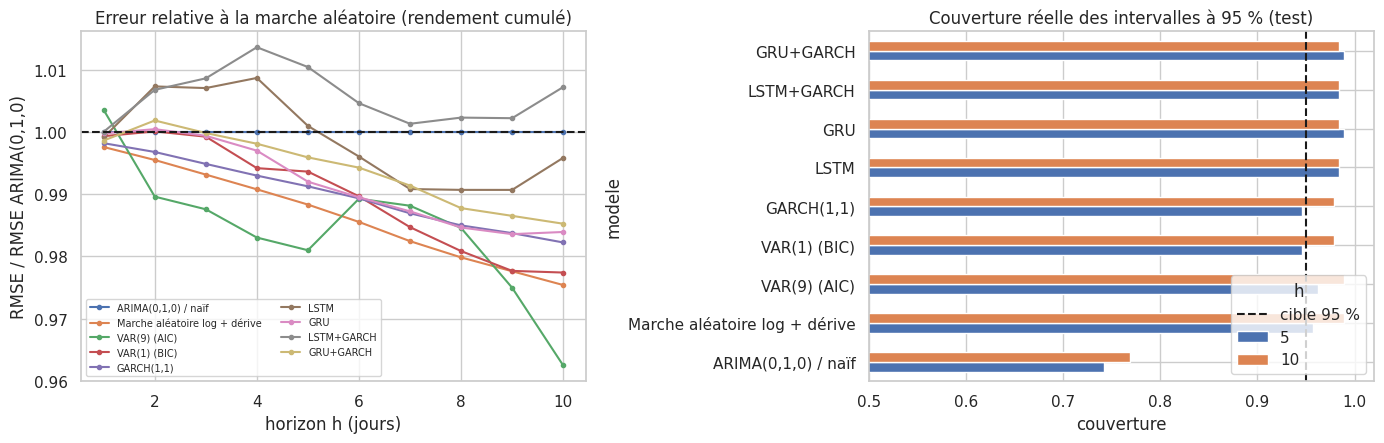

Lecture : un ratio < 1 signifie une erreur plus faible que la marche aléatoire ; une couverture < 95 % signifie un intervalle trop optimiste (trop étroit).


In [115]:
# === Graphiques d'évaluation ==========================================================
piv = res.pivot(index="h", columns="modele", values="RMSE_cum")[list(MODELS)]
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
(piv.div(piv[REF], axis=0)).plot(ax=ax[0], marker="o", ms=3)
ax[0].axhline(1, color="k", ls="--"); ax[0].set_ylabel("RMSE / RMSE ARIMA(0,1,0)"); ax[0].set_xlabel("horizon h (jours)")
ax[0].set_title("Erreur relative à la marche aléatoire (rendement cumulé)"); ax[0].legend(fontsize=7, ncol=2)
cov = res[res.h.isin([5, 10])].pivot(index="modele", columns="h", values="couverture").reindex(list(MODELS))
cov.plot.barh(ax=ax[1]); ax[1].axvline(1 - ALPHA, color="k", ls="--", label="cible 95 %"); ax[1].set_xlim(0.5, 1.02)
ax[1].set_title("Couverture réelle des intervalles à 95 % (test)"); ax[1].set_xlabel("couverture"); ax[1].legend(title="h")
plt.tight_layout(); plt.show()
print("Lecture : un ratio < 1 signifie une erreur plus faible que la marche aléatoire ; une couverture < 95 % signifie un intervalle trop optimiste (trop étroit).")

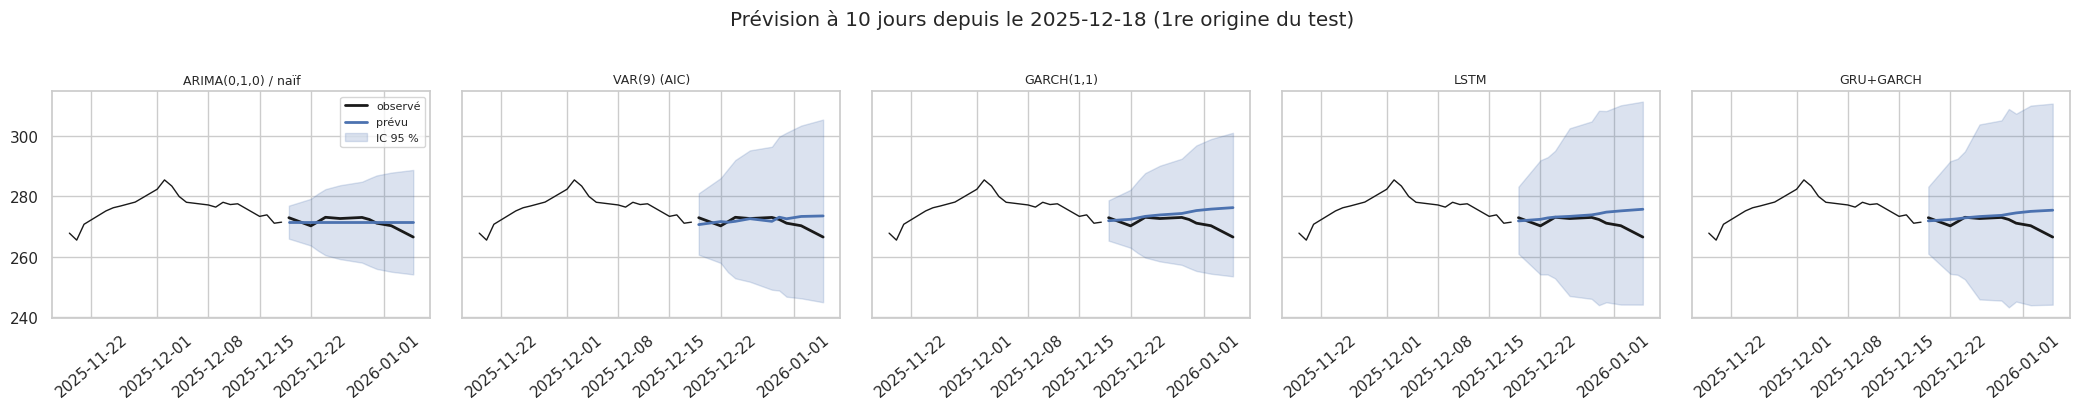

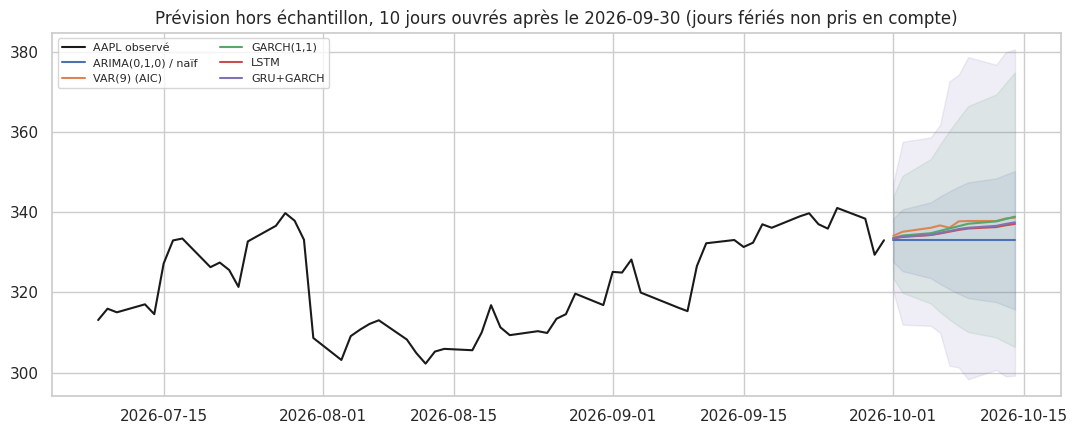

,J+1,J+2,J+3,J+4,J+5,J+6,J+7,J+8,J+9,J+10
"ARIMA(0,1,0) / naïf",333.02,333.02,333.02,333.02,333.02,333.02,333.02,333.02,333.02,333.02
Marche aléatoire log + dérive,333.39,333.77,334.14,334.51,334.89,335.26,335.64,336.01,336.39,336.76
VAR(9) (AIC),334.13,335.14,336.13,336.72,336.14,337.73,337.82,337.82,338.44,338.67
VAR(1) (BIC),333.32,333.74,334.14,334.54,334.93,335.33,335.73,336.13,336.53,336.93
"GARCH(1,1)",333.60,334.19,334.78,335.36,335.95,336.54,337.13,337.72,338.32,338.91
LSTM,333.52,333.84,334.33,334.71,335.16,335.60,335.95,336.31,336.75,337.09
GRU,333.49,333.98,334.38,334.80,335.18,335.64,336.02,336.49,336.98,337.53
LSTM+GARCH,333.56,333.86,334.34,334.84,335.45,335.89,336.32,336.75,337.17,337.54
GRU+GARCH,333.47,333.99,334.35,334.88,335.33,335.81,336.13,336.60,337.08,337.49


Modèles non ré-ajustés après le train : prévision « telle qu'évaluée ». En production, on les ré-estimerait régulièrement.


In [116]:
# === Éventails de prévision (fan charts) à partir de la 1re origine du test et à partir de la dernière date ===
show = [REF, f"VAR({p_aic}) (AIC)", "GARCH(1,1)", "LSTM", "GRU+GARCH"]
show = [m for m in show if m in MODELS]
i0 = 0; o0 = ORIG[i0]; days = dates[o0 + 1:o0 + H + 1]
fig, ax = plt.subplots(1, len(show), figsize=(4.2 * len(show), 4), sharey=True)
for a, nm in zip(np.atleast_1d(ax), show):
    m = MODELS[nm]
    a.plot(dates[o0 - 20:o0 + 1], PX[o0 - 20:o0 + 1], "k", lw=1); a.plot(days, P_fut[i0], "k", lw=2, label="observé")
    a.plot(days, P_o[i0] * np.exp(m["R"][i0]), "C0", lw=2, label="prévu"); a.fill_between(days, m["lo"][i0], m["hi"][i0], color="C0", alpha=.2, label="IC 95 %")
    a.set_title(nm, fontsize=9); a.tick_params(axis="x", rotation=40)
np.atleast_1d(ax)[0].legend(fontsize=8); plt.suptitle(f"Prévision à 10 jours depuis le {dates[o0].date()} (1re origine du test)", y=1.02); plt.tight_layout(); plt.show()

# Prévision hors échantillon : les 10 jours ouvrés qui suivent la dernière date des données
fut = pd.bdate_range(dates[-1] + pd.Timedelta(days=1), periods=H)
fig, a = plt.subplots(figsize=(11, 4.5))
a.plot(dates[-60:], PX[-60:], "k", lw=1.5, label="AAPL observé")
for nm, c in zip(show, ["C0", "C1", "C2", "C3", "C4"]):
    m = MODELS[nm]; a.plot(fut, PX[-1] * np.exp(m["R_fwd"]), c, lw=1.5, label=nm)
    if nm in (REF, "GARCH(1,1)", "GRU+GARCH"): a.fill_between(fut, m["lo_fwd"], m["hi_fwd"], color=c, alpha=.12)
a.set_title(f"Prévision hors échantillon, 10 jours ouvrés après le {dates[-1].date()} (jours fériés non pris en compte)"); a.legend(fontsize=8, ncol=2); plt.tight_layout(); plt.show()
fwd = pd.DataFrame({nm: dict(zip([f"J+{h}" for h in range(1, H + 1)], np.round(PX[-1] * np.exp(m["R_fwd"]), 2))) for nm, m in MODELS.items()}).T
fwd.to_csv(f"{OUT_DIR}/forecast_forward_part6.csv"); display(fwd)
print("Modèles non ré-ajustés après le train : prévision « telle qu'évaluée ». En production, on les ré-estimerait régulièrement.")

## 6.4 — Choix du meilleur modèle selon le cas d'usage

L'énoncé demande de conclure **en tenant compte non seulement de la performance mais aussi de l'interprétabilité et du coût de calcul**. Trois cas d'usage différents ne conduisent pas forcément au même modèle :

1. **Prévision ponctuelle du prix à 5-10 jours** → critère : RMSE du rendement cumulé, *à condition que l'écart avec la marche aléatoire soit statistiquement significatif* ; sinon on garde le modèle le plus simple.
2. **Mesure du risque / gestion de l'incertitude** → critère : intervalles bien calibrés (couverture proche de 95 %) et score de Winkler faible.
3. **Explication à un décideur** → critère : interprétabilité (on peut dire *pourquoi* le modèle prévoit cela).

L'interprétabilité (échelle 1-5) est un **jugement de l'équipe**, pas une mesure : ARIMA / marche aléatoire (5 : une formule), VAR et GARCH (4 : coefficients lisibles, effets de retards et de volatilité), réseaux (2 : boîte grise).

In [117]:
# === Tableau de décision : performance × significativité × coût × interprétabilité ===
INTERP = {REF: 5, "Marche aléatoire log + dérive": 5, "GARCH(1,1)": 4, "LSTM": 2, "GRU": 2, "LSTM+GARCH": 2, "GRU+GARCH": 2}
for nm in MODELS: INTERP.setdefault(nm, 4 if nm.startswith("VAR") else 2)
h_mid = res[res.h.between(5, 10)]
g = h_mid.groupby("modele")
dec = pd.DataFrame({
    "RMSE_cum relatif (h=5..10)": (g["RMSE_cum"].mean() / g["RMSE_cum"].mean()[REF]),
    "signif. meilleur (h=5 ou 10)": res[res.h.isin([5, 10])].assign(ok=lambda d: (d.p_DM_cum < 0.05) & (d.DM_cum < 0)).groupby("modele")["ok"].any(),
    "signif. meilleur que RW+dérive (h=5 ou 10)": res[res.h.isin([5, 10])].assign(ok=lambda d: (d.p_DM_vs_derive < 0.05) & (d.DM_vs_derive < 0)).groupby("modele")["ok"].any(),
    "écart couverture/95 % (h=5,10)": res[res.h.isin([5, 10])].assign(e=lambda d: (d.couverture - (1 - ALPHA)).abs()).groupby("modele")["e"].mean(),
    "Winkler moyen (h=5..10)": g["winkler"].mean(),
    "paramètres": pd.Series({k: m["n_params"] for k, m in MODELS.items()}),
    "temps d'ajustement (s)": pd.Series({k: m["fit_time"] for k, m in MODELS.items()}),
    "interprétabilité (1-5)": pd.Series(INTERP)}).reindex(list(MODELS))
display(dec.round(4))
dec.to_csv(f"{OUT_DIR}/decision_matrix_part6.csv")

# --- Verdict automatique (à reprendre dans le rapport avec VOS chiffres) ---
cand = [m for m in dec.index if m != REF and dec.loc[m, "signif. meilleur (h=5 ou 10)"]]
print("\n● CAS 1 — prévision ponctuelle à 5-10 jours")
if cand:
    b = min(cand, key=lambda m: dec.loc[m, "RMSE_cum relatif (h=5..10)"])
    rel, npar, tfit, interp = dec.loc[b, "RMSE_cum relatif (h=5..10)"], dec.loc[b, "paramètres"], dec.loc[b, "temps d'ajustement (s)"], dec.loc[b, "interprétabilité (1-5)"]
    print(f"  {b} bat significativement ARIMA(0,1,0) (Diebold-Mariano, α=5 %) avec une erreur relative de {rel:.3f} ; coût : {npar:.0f} paramètres, {tfit:.0f} s ; interprétabilité {interp}/5.")
    if b != REF2 and not dec.loc[b, "signif. meilleur que RW+dérive (h=5 ou 10)"]:
        print("  ⚠ mais il ne bat PAS significativement la marche aléatoire avec dérive : son avantage sur le naïf vient surtout de la dérive moyenne (rendement positif de la période).")
else:
    simple = [m for m in dec.index if dec.loc[m, "interprétabilité (1-5)"] == 5]
    b_s = min(simple, key=lambda m: dec.loc[m, "RMSE_cum relatif (h=5..10)"]); rel_s = dec.loc[b_s, "RMSE_cum relatif (h=5..10)"]
    best_raw = dec["RMSE_cum relatif (h=5..10)"].idxmin(); rel_b = dec.loc[best_raw, "RMSE_cum relatif (h=5..10)"]
    print(f"  Aucun modèle ne bat significativement ARIMA(0,1,0). Plus faible RMSE brut : {best_raw} ({rel_b:.3f} × la référence), écart non significatif.")
    print(f"  → on retient le modèle le plus simple (interprétabilité 5/5) à plus faible erreur : {b_s} ({rel_s:.3f} × la référence).")
print("\n● CAS 2 — mesure de l'incertitude")
ok_int = dec.dropna(subset=["écart couverture/95 % (h=5,10)"])
b2 = ok_int["écart couverture/95 % (h=5,10)"].idxmin(); b3 = ok_int["Winkler moyen (h=5..10)"].idxmin()
print(f"  Couverture la plus proche de 95 % : {b2} (écart moyen {ok_int.loc[b2, 'écart couverture/95 % (h=5,10)']:.3f}) ; plus faible score de Winkler : {b3} ({ok_int.loc[b3, 'Winkler moyen (h=5..10)']:.2f}).")
print("\n● CAS 3 — explication à un décideur : modèles les plus interprétables et dont les performances ne sont pas significativement pires :")
print("  ", [m for m in dec.index if dec.loc[m, "interprétabilité (1-5)"] >= 4])

,RMSE_cum relatif (h=5..10),signif. meilleur (h=5 ou 10),signif. meilleur que RW+dérive (h=5 ou 10),"écart couverture/95 % (h=5,10)",Winkler moyen (h=5..10),paramètres,temps d'ajustement (s),interprétabilité (1-5)
"ARIMA(0,1,0) / naïf",1.0000,False,False,0.1946,91.7255,1,0.0465,5
Marche aléatoire log + dérive,0.9811,False,False,0.0231,61.8276,2,0.0000,5
VAR(9) (AIC),0.9794,False,False,0.0258,57.0376,38,0.0165,4
VAR(1) (BIC),0.9834,False,False,0.0161,59.8844,6,0.0134,4
"GARCH(1,1)",0.9861,False,False,0.0161,57.2086,4,0.0321,4
LSTM,0.9940,False,False,0.0339,66.5999,4938,29.2898,2
GRU,0.9865,False,False,0.0366,66.3574,3882,29.6078,2
LSTM+GARCH,1.0046,False,False,0.0339,67.3749,5066,29.1153,2
GRU+GARCH,0.9898,False,False,0.0366,67.0396,3978,38.0711,2



● CAS 1 — prévision ponctuelle à 5-10 jours
  Aucun modèle ne bat significativement ARIMA(0,1,0). Plus faible RMSE brut : VAR(9) (AIC) (0.979 × la référence), écart non significatif.
  → on retient le modèle le plus simple (interprétabilité 5/5) à plus faible erreur : Marche aléatoire log + dérive (0.981 × la référence).

● CAS 2 — mesure de l'incertitude
  Couverture la plus proche de 95 % : VAR(1) (BIC) (écart moyen 0.016) ; plus faible score de Winkler : VAR(9) (AIC) (57.04).

● CAS 3 — explication à un décideur : modèles les plus interprétables et dont les performances ne sont pas significativement pires :
   ['ARIMA(0,1,0) / naïf', 'Marche aléatoire log + dérive', 'VAR(9) (AIC)', 'VAR(1) (BIC)', 'GARCH(1,1)']


### Comment rédiger la conclusion de la partie 6 (avec VOS chiffres)

1. **Ce que les chiffres montrent** : citer, pour h = 5 et h = 10, le RMSE du rendement cumulé de chaque famille (économétrique, réseau, hybride) **relatif à la marche aléatoire**, et les p-values du Diebold-Mariano. Rapporter les résultats non significatifs tels quels.
2. **L'horizon** : l'erreur croît avec $h$ (≈ $\sqrt h$ pour une marche aléatoire) ; si l'écart relatif d'un modèle se réduit ou s'amplifie avec $h$, le dire (premier graphique).
3. **Les intervalles** : ARIMA(0,1,0) estime une variance **constante en dollars** alors que le prix a plus que doublé sur la période → ses intervalles sont structurellement mal calibrés (comparer sa couverture à celle de la marche aléatoire *en log*). Le GARCH adapte la largeur à la volatilité du moment ; les réseaux conformaux ont une largeur **fixe** par horizon (honnête en moyenne, pas en période de crise).
4. **Le cas d'usage tranche** : à performance ponctuelle statistiquement égale, on choisit le modèle simple pour la prévision et un modèle de volatilité (GARCH) pour le risque ; un réseau n'est justifié que s'il gagne **significativement** — ce qu'on ne peut pas affirmer sans le test.
5. **Limites** (critère « honnêteté scientifique ») : une seule période de test (195 jours, marché haussier), paramètres non ré-estimés au fil du temps, intervalles du GARCH gaussiens, calibration conformale légèrement optimiste, peu d'observations indépendantes à h = 10.